# Proyecto MAI, Grupo 6: pipeline completo

Notebook único y autocontenido para la entrega. Reúne, en orden, los cinco notebooks del pipeline:

1. **Descarga** de los Financial Statement Data Sets de la SEC (`zips/`).
2. **Construcción del dataset**: `data/sub.csv` y `data/num.csv`.
3. **Fecha de quiebra** de cada empresa: `data/bankruptcy.csv`.
4. **Panel** de empresas por trimestre: `data/panel.csv`.
5. **EDA** del panel.

Las dos celdas siguientes tienen los imports y las constantes que comparten todas las partes. Las carpetas `zips/` y `data/` se crean junto a este notebook.

In [1]:
import os
import time
import zipfile
from glob import glob
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests


WORKING_DIR = Path.cwd()  # carpeta del notebook: acá van zips/ y data/

In [2]:
# Concepto -> tags XBRL en orden de prioridad. Tags de la guía de la profesora y de docs/rumbo-mai.pdf.
CONCEPTS = {
    # Ingresos netos totales
    "ingresos_netos": [
        "Revenues",
        "SalesRevenueNet",
        "RevenueFromContractWithCustomerExcludingAssessedTax",
        # no es de la profesora: el mismo ingreso con los impuestos cobrados
        "RevenueFromContractWithCustomerIncludingAssessedTax",
    ],
    # Resultado operativo (EBIT)
    "resultado_operativo": ["OperatingIncomeLoss"],
    # Resultado neto (ProfitLoss incluye a los accionistas minoritarios)
    "resultado_neto": ["NetIncomeLoss", "ProfitLoss"],
    # Activos totales
    "activos_totales": ["Assets"],
    # Activos corrientes
    "activos_corrientes": ["AssetsCurrent"],
    # Pasivos totales
    "pasivos_totales": ["Liabilities"],
    # Pasivos corrientes
    "pasivos_corrientes": ["LiabilitiesCurrent"],
    # Patrimonio neto
    "patrimonio_neto": [
        "StockholdersEquity",
        "StockholdersEquityAttributableToParent",
    ],
    # Flujo de caja operativo
    "flujo_caja_operativo": [
        "NetCashProvidedByUsedInOperatingActivities",
        "NetCashProvidedByUsedInOperatingActivitiesContinuingOperations",
    ],
    # Ganancia bruta. Si falta, la parte 4 la construye: ingresos_netos - costo_ventas
    "ganancia_bruta": ["GrossProfit"],
    # Caja
    "caja": [
        "CashAndCashEquivalentsAtCarryingValue",
        "CashCashEquivalentsRestrictedCashAndRestrictedCashEquivalents",
    ],
    # Costo de ventas: solo para construir la ganancia bruta, no queda en el panel
    "costo_ventas": ["CostOfRevenue", "CostOfGoodsSold"],
}

# Conceptos que miden un período (qtrs de 1 a 4). Los demás son saldos a una fecha (qtrs = 0).
FLOWS = [
    "ingresos_netos",
    "resultado_operativo",
    "resultado_neto",
    "flujo_caja_operativo",
    "ganancia_bruta",
    "costo_ventas",
]

# Trimestres calendario del panel, 2018Q1-2024Q4
TRIMESTRES = pd.period_range("2018Q1", "2024Q4", freq="Q")
N_TRIMESTRES = len(TRIMESTRES)  # 28

# Trimestres que los gráficos sombrean como COVID (primero y último, inclusive)
COVID = ("2020Q1", "2021Q4")

# Descarga de los Financial Statement Data Sets de la SEC

Descarga un zip por trimestre en `zips/`, sin descomprimir.

El período de análisis es 2018Q1–2024Q4 (`docs/rumbo-mai.pdf`), pero se descarga hasta `2025q4` porque el zip se nombra por la fecha de presentación. El 10-K de 2024 se presenta en 2025.

La SEC rechaza la descarga (error 403) si el `User-Agent` no tiene un email de contacto.

In [3]:
START, END = 2018, 2025
quarters = [
    f"{y}q{q}"
    for y in range(START, END + 1)  # loop through years
    for q in range(1, 5)  # loop through quarters
]
quarters[:4]  # first 4 quarters


['2018q1', '2018q2', '2018q3', '2018q4']

### ACLARACION: 

- El URL es el del link de descarga de los archivos que aparece en la pagina https://www.sec.gov/data-research/sec-markets-data/financial-statement-data-sets.
- El URL en el navegador funciona solo, pero para descargarlo a travez de un script hay que identificarse de alguna forma. 

In [4]:
URL = "https://www.sec.gov/files/dera/data/financial-statement-data-sets/{}.zip"
EMAIL = "ejemplo@ejemplo.com"  # no se verifica el correo, pero es necesario para descargar! (con ejemplo@ejemplo.com funciona)
HEADERS = {"User-Agent": f"Diplodatos UNC {EMAIL}"}

OUT_DIR = f"{WORKING_DIR}/zips"
os.makedirs(OUT_DIR, exist_ok=True)


for quarter in quarters:
    file = f"{OUT_DIR}/{quarter}.zip"

    # Si un zip ya existe, no se descarga otra vez.
    if os.path.exists(file):
        print(f"El archivo {quarter}.zip: ya existe, no se descarga otra vez.")
        continue

    url = URL.format(quarter)
    response = requests.get(url, headers=HEADERS)
    response.raise_for_status()  # error if the SEC does not answer 200

    with open(file, "wb") as f:
        f.write(response.content)

    print(f"{quarter}.zip descargado  ({os.path.getsize(file) / 1e6:.0f} MB)")

El archivo 2018q1.zip: ya existe, no se descarga otra vez.
El archivo 2018q2.zip: ya existe, no se descarga otra vez.
El archivo 2018q3.zip: ya existe, no se descarga otra vez.
El archivo 2018q4.zip: ya existe, no se descarga otra vez.
El archivo 2019q1.zip: ya existe, no se descarga otra vez.
El archivo 2019q2.zip: ya existe, no se descarga otra vez.
El archivo 2019q3.zip: ya existe, no se descarga otra vez.
El archivo 2019q4.zip: ya existe, no se descarga otra vez.
El archivo 2020q1.zip: ya existe, no se descarga otra vez.
El archivo 2020q2.zip: ya existe, no se descarga otra vez.
El archivo 2020q3.zip: ya existe, no se descarga otra vez.
El archivo 2020q4.zip: ya existe, no se descarga otra vez.
El archivo 2021q1.zip: ya existe, no se descarga otra vez.
El archivo 2021q2.zip: ya existe, no se descarga otra vez.
El archivo 2021q3.zip: ya existe, no se descarga otra vez.
El archivo 2021q4.zip: ya existe, no se descarga otra vez.
El archivo 2022q1.zip: ya existe, no se descarga otra ve

Verificación: cada zip tiene los cuatro archivos.

In [5]:
# leemos la info de todos los zip, vemos que en cada uno esten los 4 archivos que esperamos, y si no, tiramos un error.

for quarter in quarters:
    with zipfile.ZipFile(f"{OUT_DIR}/{quarter}.zip") as z:
        missing = {"sub.txt", "num.txt", "pre.txt", "tag.txt"} - set(z.namelist())

    assert not missing, f"{quarter}: missing {missing}"

# vemos cuanto ocupan todos los zips juntos, y cuantos zips tenemos.


print("Cantidad de archivos descargados:", len(quarters))
total = sum(os.path.getsize(f"{OUT_DIR}/{q}.zip") for q in quarters)
print(f"Tamaño total: {total / 1e6:.2f} MB")


Cantidad de archivos descargados: 32
Tamaño total: 3217.99 MB


# Construcción del dataset

Paso 1: juntar en un solo archivo las submissions (`sub.txt`) de salud y energía de todos los zips.

In [6]:
SECTORS = {
    "salud": (8000, 8099),
    "energia": (1300, 1399),
}

# `glob` lo que hace es listar los que cumplen el patron del argumento, `sorted` los ordena alfabeticamente
ZIPS = sorted(glob(f"{WORKING_DIR}/zips/*.zip"))

DATA_DIR = f"{WORKING_DIR}/data"
os.makedirs(DATA_DIR, exist_ok=True)

print("Primeros 5 archivos zip:", ZIPS[:5])
print(f"Se encontraron {len(ZIPS)} archivos zip")

Primeros 5 archivos zip: ['/home/ebner/FAMAF/Diplodatos/MAI/src/zips/2018q1.zip', '/home/ebner/FAMAF/Diplodatos/MAI/src/zips/2018q2.zip', '/home/ebner/FAMAF/Diplodatos/MAI/src/zips/2018q3.zip', '/home/ebner/FAMAF/Diplodatos/MAI/src/zips/2018q4.zip', '/home/ebner/FAMAF/Diplodatos/MAI/src/zips/2019q1.zip']
Se encontraron 32 archivos zip


Cada fila de `sub.txt` es un documento presentado a la SEC. La columna `sector` dice si la empresa es de salud o de energía, y la columna `zip` dice de qué zip salió la fila. Solo se leen las columnas de `SUB_COLS`.

In [7]:
# the other 25 columns of sub.txt (addresses, former names, afs, XBRL file details) are not read: docs/decisions.md, section 4
SUB_COLS = [
    "adsh",
    "cik",
    "name",
    "sic",
    "fye",
    "form",
    "period",
    "fy",
    "fp",
    "filed",
    "prevrpt",
]


def read_sub(path: str) -> pd.DataFrame:

    with zipfile.ZipFile(path) as z, z.open("sub.txt") as f:
        submission = pd.read_csv(f, sep="\t", dtype=str, usecols=SUB_COLS)

    sic = pd.to_numeric(submission["sic"], errors="coerce")

    submission["sector"] = None

    for sector, (low, high) in SECTORS.items():
        submission.loc[sic.between(low, high), "sector"] = sector

    # Agregamos una columna con el nombre del zip, para poder identificar de donde viene cada submission
    submission["zip"] = path.split("/")[-1].removesuffix(".zip")
    return submission.dropna(subset=["sector"])


submissions = pd.concat([read_sub(p) for p in ZIPS], ignore_index=True)
submissions.shape

(9918, 13)

Documentos y empresas por sector, y tipos de documento más comunes.

In [8]:
# agrupar la cantidad de documentos y empresas por sector
submissions.groupby("sector").agg(
    submissions=("adsh", "count"),
    companies=("cik", "nunique"),
    # `nunique` cuenta la cantidad de valores distintos (`unique` te da los valores unicos)
)


,submissions,companies
sector,,
energia,6389,379
salud,3529,203


In [9]:
# 10-K y 10-Q, con sus enmiendas (/A). docs/decisions.md, sección 3.
submissions = submissions[
    submissions["form"].isin(["10-K", "10-Q", "10-K/A", "10-Q/A"])
]
submissions["form"].value_counts()

form
10-Q      6513
10-K      2184
10-Q/A     161
10-K/A      97
Name: count, dtype: int64

In [10]:
# each submission appears in only one zip
assert submissions["adsh"].is_unique


In [11]:
submissions.to_csv(f"{DATA_DIR}/sub.csv", index=False)

In [12]:
submissions.head(5)

,adsh,cik,name,sic,fye,form,period,fy,fp,filed,prevrpt,sector,zip
1,0001185185-18-000404,719209,ISRAMCO INC,1311,1231,10-K,20171231,2017,FY,20180313,0,energia,2018q1
2,0001193125-18-041668,949039,"DIAMOND OFFSHORE DRILLING, INC.",1381,1231,10-K,20171231,2017,FY,20180213,0,energia,2018q1
3,0000318996-18-000007,318996,KEY ENERGY SERVICES INC,1389,1231,10-K,20171231,2017,FY,20180228,0,energia,2018q1
5,0000930413-18-000950,316253,ENZO BIOCHEM INC,8071,0731,10-Q,20180131,2018,Q2,20180312,0,salud,2018q1
6,0001214659-18-002003,1364397,RIDGEWOOD ENERGY T FUND LLC,1382,1231,10-K,20171231,2017,FY,20180309,0,energia,2018q1


Paso 2: leer `num.txt` de cada zip y quedarse con los números de los documentos de `submissions`.

`segments` vacío y `coreg` vacío dejan solo los números de la empresa consolidada entera.

In [13]:
NUM_COLS = [
    "adsh",
    "tag",
    "version",
    "ddate",
    "qtrs",
    "uom",
    "segments",
    "coreg",
    "value",
]
US_GAAP_TAXONOMY = [f"us-gaap/{year}" for year in range(2000, 2028)]


def read_num(path: str, adsh: set) -> pd.DataFrame:
    print(f"Reading {path}...")
    with zipfile.ZipFile(path) as z, z.open("num.txt") as f:
        num = pd.read_csv(f, sep="\t", dtype=str, usecols=NUM_COLS)

    num = num[
        num["adsh"].isin(adsh)
        # drops company-defined tags
        & num["version"].isin(US_GAAP_TAXONOMY)
        # drops periods longer than a year
        & num["qtrs"].isin(["0", "1", "2", "3", "4"])
        & num["segments"].isna()
        & num["coreg"].isna()
        # drops non-USD values
        & (num["uom"] == "USD")
    ]
    num = num.dropna(subset=["value"]).drop(columns=["segments", "coreg", "uom"])
    return num


adsh_list = set(submissions["adsh"])
numbers = pd.concat([read_num(p, adsh_list) for p in ZIPS], ignore_index=True)  # ~3 min
numbers.shape

Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2018q1.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2018q2.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2018q3.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2018q4.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2019q1.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2019q2.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2019q3.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2019q4.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2020q1.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2020q2.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2020q3.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2020q4.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2021q1.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2021q2.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI/src/zips/2021q3.zip...
Reading /home/ebner/FAMAF/Diplodatos/MAI

(1643181, 6)

In [14]:
numbers.head()

,adsh,tag,version,ddate,qtrs,value
0,0001609253-18-000041,AdjustmentsToAdditionalPaidInCapitalSharebased...,us-gaap/2016,20151231,4,30000000.0000
1,0001564590-18-004217,PaymentsToAcquireFurnitureAndFixtures,us-gaap/2017,20161231,4,96000.0000
2,0001518832-18-000003,AssetsOfDisposalGroupIncludingDiscontinuedOper...,us-gaap/2017,20161231,0,12000000.0000
3,0001537028-18-000029,EarningsPerShareBasicAndDiluted,us-gaap/2017,20161231,4,-0.6700
4,0001652133-18-000009,DeferredIncomeTaxExpenseBenefit,us-gaap/2017,20151231,4,3543000.0000


Paso 3: elegir una versión de cada número.

El mismo número (empresa + concepto + período) aparece en varios documentos: el original, el comparativo de documentos posteriores y a veces una enmienda (`/A`). La regla sale de `docs/rumbo-mai.pdf`: se aceptan las correcciones presentadas hasta el 31/12/2023 (`CUTOFF`) y no las posteriores. Es una foto de la base al 31/12/2023:

- Si el número tiene versiones presentadas hasta `CUTOFF`, gana la **última** de ellas (incluye enmiendas y comparativos).
- Si no, gana la **primera** presentada después de `CUTOFF`. Así los números de 2024 quedan como se publicaron por primera vez.

Se ordena por `filed` y `form`. Si dos documentos tienen el mismo `filed`, `form` desempata: `"10-Q"` va antes que `"10-Q/A"`, así que antes del corte gana la enmienda y después el original.

`filed` queda en el resultado: es la fecha en que se conoció la versión elegida. Ver `docs/decisions.md`, sección 8.

In [15]:
KEY = ["cik", "tag", "ddate", "qtrs"]
CUTOFF = "20231231"  # `filed` is AAAAMMDD, so text order = date order

numbers = numbers.merge(
    submissions[["adsh", "cik", "form", "filed"]], on="adsh"
).sort_values(["filed", "form"])
# ultima version de todos los numeros publicados antes de CUTOFF
before = numbers[numbers["filed"] <= CUTOFF].drop_duplicates(KEY, keep="last")
after = numbers[numbers["filed"] > CUTOFF].drop_duplicates(KEY, keep="first")

# a version filed before the cutoff wins over any version filed after it
numbers_chosen = pd.concat([before, after]).drop_duplicates(KEY, keep="first")
numbers_chosen.shape

(914961, 9)

In [16]:
# cuántos números elegidos salen de una enmienda
numbers_chosen["form"].value_counts()

form
10-Q      658800
10-K      238800
10-Q/A     11614
10-K/A      5747
Name: count, dtype: int64

Paso 4: trimestre calendario de cada número.

`quarter` es el trimestre calendario que contiene más meses del trimestre fiscal que termina en `ddate` (`docs/decisions.md`, sección 11). En código: restar un mes y tomar el trimestre.

Un trimestre fiscal son 3 meses seguidos y `ddate` es el último día. El mes del medio (el de cierre menos 1) siempre cae en el trimestre calendario que tiene 2 o 3 de esos meses. Ejemplos:

- Cierre el 31 de marzo (enero, febrero, marzo): 2018Q1.
- Cierre el 31 de enero de 2019 (noviembre, diciembre, enero): 2018Q4.
- Cierre el 28 de febrero (diciembre, enero, febrero): Q1.

Para los flujos acumulados (`qtrs` de 2 a 4), `quarter` es el trimestre de su último mes: el del trimestre que se calcula restando acumulados en la parte 4 (panel).

In [17]:
def quarter(ddate: pd.Series) -> pd.Series:
    """Calendar quarter with most months of the fiscal quarter that ends in `ddate` (decisions.md, section 11)."""
    month = pd.to_datetime(ddate, format="%Y%m%d").dt.to_period("M")
    # pd.Series: the pandas stubs type .dt.asfreq as PeriodArray, at runtime it is already a Series
    return pd.Series((month - 1).dt.asfreq("Q"), index=ddate.index).astype(str)


numbers_chosen["quarter"] = quarter(numbers_chosen["ddate"])
numbers_chosen["quarter"].value_counts().sort_index().tail(8)

quarter
2023Q4    21933
2024Q1    19205
2024Q2    23995
2024Q3    24025
2024Q4    18835
2025Q1    16618
2025Q2    20728
2025Q3    20619
Name: count, dtype: int64

In [18]:
numbers_chosen.head()

,adsh,tag,version,ddate,qtrs,value,cik,form,filed,quarter
568,0001515971-18-000014,OilAndGasSalesRevenue,us-gaap/2017,20161130,3,332041.0000,1164256,10-Q,20180112,2016Q4
577,0001515971-18-000014,RepaymentsOfLinesOfCredit,us-gaap/2017,20161130,3,30000.0000,1164256,10-Q,20180112,2016Q4
919,0001515971-18-000014,OperatingIncomeLoss,us-gaap/2017,20161130,3,-699458.0000,1164256,10-Q,20180112,2016Q4
1128,0001515971-18-000014,OtherNonoperatingIncomeExpense,us-gaap/2017,20161130,1,-2232899.0000,1164256,10-Q,20180112,2016Q4
1203,0001515971-18-000014,OtherNotesPayableCurrent,us-gaap/2017,20171130,0,9157794.0000,1164256,10-Q,20180112,2017Q4


In [19]:
numbers_chosen.isna().sum()

adsh       0
tag        0
version    0
ddate      0
qtrs       0
value      0
cik        0
form       0
filed      0
quarter    0
dtype: int64

In [20]:
numbers_chosen.to_csv(f"{DATA_DIR}/num.csv", index=False)

# Fecha de quiebra de cada empresa

Este notebook busca, para cada empresa de `data/sub.csv`, la fecha en que pidió la quiebra dentro del período de estudio.

**La fuente.** Desde agosto de 2004, una empresa que pide la quiebra (Chapter 7 o Chapter 11) presenta un Form 8-K con el ítem 1.03 ("Bankruptcy or Receivership") dentro de los 4 días hábiles. Los 8-K no están en los zips: la base de la SEC solo trae documentos con estados contables en XBRL. Por eso la consulta usa la API de la SEC (`data.sec.gov/submissions`).

La etiqueta usa solo el 8-K. Es la misma fuente de la base comercial de quiebras de Audit Analytics.

Pasos:

1. Elegir las empresas: todas las de `sub.csv`.
2. Bajar la lista de documentos de cada empresa.
3. Quedarse con los 8-K con el ítem 1.03 de una empresa.
4. Repetirlo para todas las empresas y guardar los 8-K en `data/bankruptcy_filings.csv`.
5. Elegir la fecha de quiebra dentro del período de estudio.

## Paso 1: empresas

Se consultan **todas** las empresas, no solo las que dejan de presentar. Una empresa en Chapter 11 (reorganización) sigue operando y presenta sus 10-Q. Gulfport y Chord/Oasis pidieron la quiebra en 2020 y siguieron presentando sus estados contables.

El sector y el nombre salen del documento más reciente de cada empresa, como en la parte 4 (panel).

In [21]:
sub = pd.read_csv(f"{WORKING_DIR}/data/sub.csv", dtype=str)

# one row per company: name and sector of its most recent document (sorted by `filed`)
companies = sub.sort_values("filed").groupby("cik")[["name", "sector"]].last()
companies["sector"].value_counts()
companies.head(5)

,name,sector
cik,,
1000229,CORE LABORATORIES N V,energia
1001614,"RILEY EXPLORATION PERMIAN, INC.",energia
1004724,"REGIONAL HEALTH PROPERTIES, INC",salud
10048,BARNWELL INDUSTRIES INC,energia
1006655,EVOLUTION PETROLEUM CORP,energia


## Paso 2: documentos de una empresa

`data.sec.gov/submissions/CIK##########.json` devuelve los documentos de una empresa, con el CIK completado con ceros hasta 10 dígitos. Cada 8-K tiene el campo `items` con los ítems que la empresa declara, por ejemplo `"1.03,9.01"`.

- `filings.recent` trae los últimos 1.000 documentos, aproximadamente.
- Los más viejos están en archivos extra, listados en `filings.files`. La función los lee también.
- La SEC acepta hasta 10 consultas por segundo y rechaza la consulta (error 403) si el `User-Agent` no tiene un email, igual que en la parte 1 (descarga).

In [22]:
EMAIL = "ejemplo@ejemplo.com"  # no se verifica el correo, pero es necesario (igual que en la parte 1 (descarga))
HEADERS = {"User-Agent": f"Diplodatos UNC {EMAIL}"}
BASE = "https://data.sec.gov/submissions/"


def get(path: str) -> dict:
    """One request to the submissions API."""
    time.sleep(0.1)  # SEC limit: 10 requests per second
    print(f"GET {BASE + path}")
    response = requests.get(BASE + path, headers=HEADERS, timeout=30)
    response.raise_for_status()
    return response.json()


def filings(cik: str) -> pd.DataFrame:
    """All filings of a company: `recent` plus the older extra files."""
    cik_10 = str(int(cik)).zfill(10)  # the API uses the CIK with 10 digits
    company = get(f"CIK{cik_10}.json")

    # latest ~1,000 filings
    pages = [pd.DataFrame(company["filings"]["recent"])]

    # older filings, one extra file each
    for extra in company["filings"]["files"]:
        pages.append(pd.DataFrame(get(extra["name"])))

    return pd.concat(pages, ignore_index=True)

## Paso 3: 8-K con el ítem 1.03 de una empresa

`bankruptcy_filings` devuelve las fechas de **todos** los 8-K con el ítem 1.03, de la más vieja a la más nueva. Una empresa puede tener varios:

- **Un mismo caso de quiebra tiene más de un 8-K.** El ítem 1.03 también informa la aprobación del plan de reorganización.
- **Una empresa puede tener 8-K de quiebras anteriores al período.** Por ejemplo, en 2009 y en 2020.

El paso 5 elige cuál de las fechas es la quiebra del período.

Ejemplo: Gulfport (CIK 874499) tiene dos 8-K con el ítem 1.03:

| `filingDate` | Qué es |
|---|---|
| 2020-11-16 | Pedido de quiebra |
| 2021-04-29 | Aprobación del plan de reorganización |

La celda termina con un control sobre Gulfport.

In [23]:
def bankruptcy_filings(cik: str) -> list[str]:
    """Filing dates of all 8-Ks with item 1.03 (bankruptcy), oldest first."""
    f = filings(cik)
    is_8k = f["form"].str.startswith("8-K")  # includes amendments (8-K/A)
    has_item = f["items"].str.contains("1.03", regex=False)
    return sorted(f.loc[is_8k & has_item, "filingDate"])


assert bankruptcy_filings("874499") == ["2020-11-16", "2021-04-29"]  # Gulfport

GET https://data.sec.gov/submissions/CIK0000874499.json
GET https://data.sec.gov/submissions/CIK0000874499-submissions-001.json


## Paso 4: todas las empresas

La consulta tarda unos minutos: una consulta por empresa, más los archivos extra. El resultado se guarda en `data/bankruptcy_filings.csv`, con una fila por 8-K con el ítem 1.03 (`cik`, `filing_date`). Si el archivo ya existe, el notebook lo lee y no consulta otra vez a la SEC.

El archivo guarda los 8-K de toda la historia, sin filtrar por período. Así, si el período de estudio cambia, alcanza con ejecutar de nuevo el paso 5.

El paso 5 guarda el resultado en `data/bankruptcy.csv` (`cik`, `name`, `sector`, `bankruptcy_date`), que lee la parte 4 (panel).

In [24]:
FILE = Path(f"{WORKING_DIR}/data/bankruptcy_filings.csv")

# If the file already exists, do not query the SEC again.
if FILE.exists():
    found = pd.read_csv(FILE, dtype=str)
else:
    rows = []
    for cik in companies.index:
        for date in bankruptcy_filings(cik):
            rows.append({"cik": cik, "filing_date": date})
    found = pd.DataFrame(rows, columns=["cik", "filing_date"])
    found.to_csv(FILE, index=False)

found

,cik,filing_date
0,1022646,2016-05-03
1,1022646,2017-03-16
2,1022646,2020-05-15
3,1022646,2020-05-21
4,1022646,2020-08-25
...,...,...
194,945764,2020-07-31
195,945764,2020-09-04
196,949039,2020-04-27
197,949039,2020-04-28


## Paso 5: fecha de quiebra dentro del período

El período del panel es 2018Q1–2024Q4 (`docs/rumbo-mai.pdf`). `END` llega hasta el 31/12/2025 porque el objetivo es predecir la quiebra en los próximos 2 trimestres o 1 año: una empresa del panel en 2024Q4 necesita saber si quiebra en 2025. Una quiebra posterior no interesa, por ejemplo una de 2026.

**Regla.** La fecha de quiebra es el **primer** 8-K con el ítem 1.03 dentro del período. Una empresa que quiebra no sale de la quiebra: desde ese trimestre queda sin datos y marcada como quebrada (`docs/charlar.md`). Los 8-K posteriores (aprobación del plan, salida de la reorganización) no cuentan, y los anteriores al período tampoco.

Con esta regla:

- Gulfport da 2020-11-16. El 8-K de 2021-04-29 es posterior y no cuenta.
- Ultra Petroleum tiene 8-K en 2016–2017 y en 2020: da 2020-05-15.
- Grizzly Energy (antes Vanguard Natural Resources) tiene un 8-K de 2017 y otro de 2019-04-01, su segunda quiebra: da 2019-04-01.

La celda controla la regla con estos casos antes de aplicarla.

In [25]:
START, END = (
    "2018-01-01",
    "2025-12-31",
)  # panel 2018Q1-2024Q4 plus 1 year of prediction horizon


def bankruptcy_date(dates: list[str]) -> str | None:
    """First 8-K with item 1.03 inside the study period, or None."""
    return min((d for d in dates if START <= d <= END), default=None)


dates_by_cik = found.groupby("cik")["filing_date"].apply(list)
in_period = dates_by_cik.apply(bankruptcy_date).dropna().rename("bankruptcy_date")
bankruptcy = companies.join(in_period)  # NaN: no bankruptcy in the period

bankruptcy.to_csv(f"{WORKING_DIR}/data/bankruptcy.csv")
# bankruptcy.dropna(subset=["bankruptcy_date"]).sort_values("bankruptcy_date")
bankruptcy

,name,sector,bankruptcy_date
cik,,,
1000229,CORE LABORATORIES N V,energia,NaN
1001614,"RILEY EXPLORATION PERMIAN, INC.",energia,NaN
1004724,"REGIONAL HEALTH PROPERTIES, INC",salud,NaN
10048,BARNWELL INDUSTRIES INC,energia,NaN
1006655,EVOLUTION PETROLEUM CORP,energia,NaN
...,...,...,...
945764,DENBURY INC,energia,2020-07-31
948072,BIRNER DENTAL MANAGEMENT SERVICES INC,salud,NaN
948320,"LIFEMD, INC.",salud,NaN


## Limitaciones

- **Empresas que dejan de presentar antes de la quiebra.** No presentan el 8-K, así que el notebook no las detecta.
- **Quiebras de filiales.** Un 8-K con el ítem 1.03 puede informar la quiebra de una filial y no la de la empresa. El notebook la cuenta como quiebra de la empresa.
- **Quiebra empezada antes de 2018.** Si el pedido es anterior al período y un 8-K posterior (por ejemplo, la aprobación del plan) cae dentro, la empresa queda quebrada en la fecha de ese 8-K. Hoy no pasa en los datos.
- **Chapter 7 o Chapter 11.** El ítem 1.03 no los distingue. El Chapter 7 es la liquidación y el Chapter 11 la reorganización. Separarlos obliga a leer el texto del 8-K.
- **Compras y otras salidas.** Este notebook solo busca la quiebra. Una compra se detecta con el ítem 2.01 junto con la salida de la empresa (Form 15 o Form 25 y ninguna presentación posterior). PRECAUCIÓN: el ítem 2.01 también aparece cuando la empresa es la compradora.

# Panel de empresas por trimestre

El notebook arma el panel: una fila por empresa y trimestre calendario, una columna por concepto y por ratio. Sigue `docs/rumbo-mai.pdf`:

- Período 2018Q1–2024Q4.
- Empresas que quiebran y que no, pero no las que se crearon durante el período.
- Panel no balanceado: una empresa no necesita datos en todos los trimestres.
- Nombres de columnas en español.

Pasos:

1. Leer los documentos y las empresas.
2. Quedarse con los tags de `CONCEPTS` (celda de constantes, al principio).
3. Calcular los flujos trimestrales.
4. Asignar cada valor a su trimestre calendario.
5. Elegir un tag por empresa, concepto y trimestre.
6. Construir la ganancia bruta cuando falta.
7. Quedarse con las empresas que existían al inicio.
8. Cortar a las empresas que quiebran.
9. Calcular los ratios.
10. Guardar `data/panel.csv`.

Entradas: `data/sub.csv` y `data/num.csv` (salen de la parte 2 (dataset)) y `data/bankruptcy.csv` (sale de la parte 3 (quiebras)).

## Paso 1: documentos y empresas

Cada empresa tiene un solo sector y un solo nombre: los de su documento más reciente por `filed` (`docs/decisions.md`, sección 2).

In [26]:
START, END = pd.Period("2018Q1"), pd.Period("2024Q4")


sub = pd.read_csv(f"{WORKING_DIR}/data/sub.csv", dtype=str)

# columna mensual (solo tiene AAAA-MM)
sub["month"] = pd.to_datetime(sub["period"], format="%Y%m%d").dt.to_period("M")

# name and sector of the most recent document (`filed` is AAAAMMDD, so text order = date order)
companies = sub.sort_values("filed").groupby("cik")[["name", "sector"]].last()
companies.head()


,name,sector
cik,,
1000229,CORE LABORATORIES N V,energia
1001614,"RILEY EXPLORATION PERMIAN, INC.",energia
1004724,"REGIONAL HEALTH PROPERTIES, INC",salud
10048,BARNWELL INDUSTRIES INC,energia
1006655,EVOLUTION PETROLEUM CORP,energia


## Paso 2: tags de `concepts.py`

`CONCEPTS` asigna a cada concepto una lista de tags. El orden de cada lista es la prioridad: primero el tag principal, después los alternativos (`docs/decisions.md`, sección 12).

- **Flujos** (`FLOWS`): miden un período, por ejemplo los ingresos de un trimestre. Tienen `qtrs` de 1 a 4.
- **Saldos**: miden una fecha, por ejemplo los activos al cierre. Tienen `qtrs` = 0.

La celda lee de `num.csv` solo las filas con un tag de `CONCEPTS`. `quarter` es el trimestre calendario de cada número, calculado en la parte 2 (dataset) (paso 4). `filed` es la fecha en que se conoció cada número (`docs/decisions.md`, sección 8).

In [27]:
# tag -> concept, and tag -> position in its list (0 = principal tag)
CONCEPT = {t: c for c, tags in CONCEPTS.items() for t in tags}
RANK = {t: i for tags in CONCEPTS.values() for i, t in enumerate(tags)}

num = pd.read_csv(
    f"{WORKING_DIR}/data/num.csv",
    dtype={"cik": str, "ddate": str, "filed": str},
    usecols=["cik", "tag", "ddate", "qtrs", "value", "filed", "quarter"],
)
num = num[num["tag"].isin(CONCEPT)]
num["concept"] = num["tag"].map(CONCEPT)
num["month"] = pd.to_datetime(num["ddate"], format="%Y%m%d").dt.to_period("M")
# `quarter` comes from la parte 2 (dataset) (paso 4) as text: to Period, to compare with START and END
num["quarter"] = pd.PeriodIndex(num["quarter"], freq="Q")
num

# num.groupby("qtrs").size()

,tag,ddate,qtrs,value,cik,filed,quarter,concept,month
2,OperatingIncomeLoss,20161130,3,-699458.0,1164256,20180112,2016Q4,resultado_operativo,2016-11
7,LiabilitiesCurrent,20171130,0,15303879.0,1164256,20180112,2017Q4,pasivos_corrientes,2017-11
11,Liabilities,20171130,0,15911116.0,1164256,20180112,2017Q4,pasivos_totales,2017-11
24,CashAndCashEquivalentsAtCarryingValue,20161130,0,20494.0,1164256,20180112,2016Q4,caja,2016-11
30,StockholdersEquity,20171130,0,-14801880.0,1164256,20180112,2017Q4,patrimonio_neto,2017-11
...,...,...,...,...,...,...,...,...,...
914948,NetIncomeLoss,20250630,1,-1203266.0,1936756,20251223,2025Q2,resultado_neto,2025-06
914949,NetIncomeLoss,20250630,2,-2356938.0,1936756,20251223,2025Q2,resultado_neto,2025-06
914957,Revenues,20250630,1,1963.0,1936756,20251223,2025Q2,ingresos_netos,2025-06
914958,Revenues,20250630,2,5027.0,1936756,20251223,2025Q2,ingresos_netos,2025-06


## Paso 3: flujos trimestrales

El panel usa el flujo de un trimestre (`docs/decisions.md`, sección 10). Muchos documentos no lo traen: traen el acumulado desde el inicio del año fiscal.

- Si hay valor con `qtrs` = 1, se usa ese valor.
- Si no, se resta: acumulado de k trimestres menos acumulado de k − 1 trimestres que termina 3 meses antes. Los dos acumulados empiezan en el mismo mes.

Ejemplos:

- **Cuarto trimestre:** año (`qtrs` = 4, diciembre) menos 9 meses (`qtrs` = 3, septiembre). El 10-K no trae el cuarto trimestre solo.
- **Flujo operativo del segundo trimestre:** 6 meses (`qtrs` = 2, junio) menos 3 meses (`qtrs` = 1, marzo). Los 10-Q suelen traer este flujo solo acumulado.

La resta se hace con el mismo tag (`docs/decisions.md`, sección 12, regla A). Nunca mezcla dos tags. El valor restado conserva el `filed` del acumulado de k trimestres, que es el más nuevo.

La celda mueve cada acumulado de k − 1 trimestres 3 meses hacia adelante y lo une a la fila del acumulado de k trimestres. Después resta.

La tabla del final (`groupby("qtrs").size()`) no cambia los datos: cuenta de dónde salió cada valor trimestral. Después de la resta, `qtrs` conserva el número original de la fila:

| `qtrs` | Origen del valor trimestral |
|---|---|
| 1 | Reportado así en el documento (3 meses), sin resta |
| 2 | 6 meses − 3 meses |
| 3 | 9 meses − 6 meses |
| 4 | Año − 9 meses (cuarto trimestre) |

Así se ve cuánto del panel depende de la resta. Sin ella no habría ningún cuarto trimestre, porque el 10-K solo trae el año.

In [28]:
flows = num[num["concept"].isin(FLOWS)]

# the accumulated k-1 quarters, moved to the row of the accumulated k quarters (3 months later)
previous = flows.assign(month=flows["month"] + 3, qtrs=flows["qtrs"] + 1)
flows = flows.merge(
    previous[["cik", "tag", "month", "qtrs", "value"]],
    on=["cik", "tag", "month", "qtrs"],
    how="left",
    suffixes=("", "_previous"),
)
flows["value"] = flows["value"].where(
    flows["qtrs"] == 1, flows["value"] - flows["value_previous"]
)

# ponytail: "3 months before" compares months, so a 52/53-week year ending on the 1st of a month
# can miss its previous accumulated value; compare days if that matters
flows = flows.dropna(subset="value")
flows.groupby("qtrs").size()

qtrs
1    35382
2    12038
3    11923
4    10436
dtype: int64

## Verificación de la resta

Algunas fechas tienen el trimestre reportado (`qtrs` = 1) y también la resta de acumulados. La celda compara los dos valores. Si coinciden, la resta es correcta.

- **1 USD:** el valor es idéntico.
- **1.000 USD:** muchas empresas redondean a miles, así que la resta puede diferir en el último dígito.
- **1%:** una diferencia mayor indica otro problema, por ejemplo versiones de documentos distintos (`docs/decisions.md`, sección 8).

In [29]:
reported = flows[flows["qtrs"] == 1]
subtracted = flows[flows["qtrs"] > 1]
both = reported.merge(
    subtracted, on=["cik", "tag", "month"], suffixes=("_reported", "_subtracted")
)
difference = (both["value_reported"] - both["value_subtracted"]).abs()
print(f"fechas con los dos valores: {len(both)}")
print(f"diferencia <= 1 USD: {(difference <= 1).mean():.1%}")
print(f"diferencia <= 1.000 USD: {(difference <= 1000).mean():.1%}")
print(
    f"diferencia <= 1%: {(difference <= 0.01 * both['value_reported'].abs()).mean():.1%}"
)

fechas con los dos valores: 19648
diferencia <= 1 USD: 90.8%
diferencia <= 1.000 USD: 94.2%
diferencia <= 1%: 95.9%


## Paso 4: trimestre calendario

Cada valor ya tiene su trimestre calendario (`quarter`, de la parte 2 (dataset)). Antes se eliminan las fechas que no son el cierre de un documento de la empresa (`sub.period`, `docs/decisions.md`, sección 11). Dos casos:

- **Comparativos con otro calendario.** Sustainable Projects cambió su cierre de mayo a diciembre en 2019. Sus documentos nuevos traen comparativos con cierre en diciembre de 2018, y el trimestre 2018Q4 ya tiene el cierre de noviembre.
- **Subperíodos por quiebra.** Una empresa que sale de una quiebra (por ejemplo, Gulfport Energy en 2021) reporta el período antes y después de la salida por separado.

Una fecha puede tener el trimestre reportado y una o más restas. Se usa el reportado; si no hay, la resta con menos trimestres acumulados.

Una empresa que cambia el cierre de su año fiscal puede tener dos documentos con cierre en el mismo trimestre. En ese caso se usa el cierre más reciente. La celda cuenta cuántos valores se descartan por esa razón.

In [30]:
# a date can have the reported quarter and one or more subtractions: keep the smallest `qtrs` (reported first)
flows = flows.sort_values("qtrs").drop_duplicates(["cik", "tag", "month"])
stocks = num[~num["concept"].isin(FLOWS) & (num["qtrs"] == 0)]
values = pd.concat([flows, stocks])[
    ["cik", "tag", "concept", "month", "quarter", "value", "filed"]
]

# keep only the closing dates of the company's documents
values = values.merge(sub[["cik", "month"]].drop_duplicates(), on=["cik", "month"])
values = values[values["quarter"].between(START, END)]

# two closing dates in the same quarter (change of fiscal year): keep the latest
before = len(values)
values = values.sort_values("month").drop_duplicates(
    ["cik", "tag", "quarter"], keep="last"
)
print(
    f"valores descartados por dos cierres en el mismo trimestre: {before - len(values)}"
)
values

valores descartados por dos cierres en el mismo trimestre: 10


,cik,tag,concept,month,quarter,value,filed
260,1350421,OperatingIncomeLoss,resultado_operativo,2018-02,2018Q1,-5339.0,20180416
259,862692,Revenues,ingresos_netos,2018-02,2018Q1,6228118.0,20180416
258,1350421,NetIncomeLoss,resultado_neto,2018-02,2018Q1,-5339.0,20180416
250,862692,NetCashProvidedByUsedInOperatingActivitiesCont...,flujo_caja_operativo,2018-02,2018Q1,1691863.0,20180416
7066,1500305,Revenues,ingresos_netos,2018-02,2018Q1,15000.0,20190805
...,...,...,...,...,...,...,...
3464,1544400,NetCashProvidedByUsedInOperatingActivities,flujo_caja_operativo,2025-01,2024Q4,0.0,20250318
3462,1544400,Revenues,ingresos_netos,2025-01,2024Q4,0.0,20250318
3466,1544400,NetIncomeLoss,resultado_neto,2025-01,2024Q4,-924.0,20250318
3467,1544400,OperatingIncomeLoss,resultado_operativo,2025-01,2024Q4,-924.0,20250318


## Paso 5: un tag por empresa, concepto y trimestre

En cada empresa, concepto y trimestre se usa el primer tag de `CONCEPTS` con valor (regla A, `docs/decisions.md`, sección 12). Una empresa puede cambiar de tag entre trimestres.

`panel` tiene una fila por empresa y trimestre, y una columna por concepto. NaN significa que ningún tag del concepto tiene valor.

`fecha_presentacion` es el `filed` más reciente de los valores de la fila: la fecha desde la que se conoce la fila completa.

In [31]:
# principal tag first: sort by position in the list, keep the first row of each concept and quarter
chosen = values.sort_values("tag", key=lambda t: t.map(RANK)).drop_duplicates(
    ["cik", "concept", "quarter"]
)
panel = chosen.pivot(index=["cik", "quarter"], columns="concept", values="value")[
    list(CONCEPTS)
]
panel["fecha_presentacion"] = chosen.groupby(["cik", "quarter"])["filed"].max()
panel.head()

concept          ingresos_netos  resultado_operativo  resultado_neto  \
cik     quarter                                                        
1000229 2018Q1      170018000.0           32316000.0      23527000.0   
        2018Q2      175475000.0           33449000.0      24752000.0   
        2018Q3      182146000.0           34879000.0      22412000.0   
        2018Q4      173207000.0           17978000.0       8835000.0   
        2019Q1      169194000.0           16414000.0      40510000.0   

concept          activos_totales  activos_corrientes  pasivos_totales  \
cik     quarter                                                         
1000229 2018Q1       597140000.0         220185000.0              NaN   
        2018Q2       604744000.0         225662000.0              NaN   
        2018Q3       666597000.0         239125000.0              NaN   
        2018Q4       648827000.0         230977000.0              NaN   
        2019Q1       791760000.0         236423000.0              NaN   

concept          pasivos_corrientes  patrimonio_neto  flujo_caja_operativo  \
cik     quarter                                                              
1000229 2018Q1          104327000.0      147638000.0            23093000.0   
        2018Q2          100591000.0      153783000.0            26990000.0   
        2018Q3          103509000.0      157438000.0            23843000.0   
        2018Q4          102547000.0      156759000.0            37901000.0   
        2019Q1          128615000.0      183165000.0            25156000.0   

concept          ganancia_bruta        caja  costo_ventas fecha_presentacion  
cik     quarter                                                               
1000229 2018Q1              NaN  13244000.0           NaN           20200210  
        2018Q2              NaN  13021000.0           NaN           20200210  
        2018Q3              NaN  14100000.0           NaN           20200210  
        2018Q4              NaN  13116000.0           NaN           20210208  
        2019Q1              NaN  13206000.0           NaN           20210208

## Paso 6: ganancia bruta

Si falta `GrossProfit`, ganancia bruta = ingresos netos − costo de ventas, como indica la guía de la mentora (`docs/decisions.md`, sección 12). El costo de ventas solo sirve para esto y no queda en el panel.

Después se eliminan las filas que quedaron sin ningún concepto (las que solo tenían costo de ventas).

In [32]:
constructed = (
    panel["ganancia_bruta"].isna()
    & (panel["ingresos_netos"] - panel["costo_ventas"]).notna()
)
panel["ganancia_bruta"] = panel["ganancia_bruta"].fillna(
    panel["ingresos_netos"] - panel["costo_ventas"]
)
panel = panel.drop(columns="costo_ventas")

CONCEPT_COLUMNS = [c for c in CONCEPTS if c != "costo_ventas"]
panel = panel.dropna(subset=CONCEPT_COLUMNS, how="all")
print(
    f"ganancia bruta reportada: {panel['ganancia_bruta'].notna().sum() - constructed.sum()}"
)
print(f"ganancia bruta construida: {constructed.sum()}")

ganancia bruta reportada: 1188
ganancia bruta construida: 371


## Paso 7: empresas que existían al inicio

El rumbo deja afuera a las empresas que se crearon durante el período. Entra una empresa si tiene al menos un concepto con valor en 2018Q1 (`docs/decisions.md`, sección 13).

Como el paso 4 solo conserva los cierres de documentos de la empresa, en la práctica es una empresa con un 10-K o 10-Q con cierre en 2018Q1.

La celda:

1. `panel.xs(START, level="quarter")` se queda con las filas de 2018Q1 (corte transversal, *cross-section*), y `.index` toma sus `cik`: son las empresas que existían (`existing`). Como el paso 6 borró las filas vacías, tener fila es tener al menos un valor.
2. `panel.index.get_level_values("cik").isin(existing)` marca las filas de esas empresas. El filtro es por empresa: quedan **todos** sus trimestres, no solo 2018Q1.
3. `value_counts()` cuenta las empresas que quedan por sector. Solo muestra el resultado.

In [33]:
existing = panel.xs(START, level="quarter").index
panel = panel[panel.index.get_level_values("cik").isin(existing)]
companies.loc[existing, "sector"].value_counts()  # empresas que quedaron.

sector
energia    246
salud       86
Name: count, dtype: int64

## Paso 8: quiebras

La fecha de quiebra es la del 8-K con el ítem 1.03, de la parte 3 (quiebras) (`data/bankruptcy.csv`). En el panel, una empresa que quiebra deja de tener filas desde el trimestre calendario de la quiebra (`docs/decisions.md`, sección 13). Por ejemplo, una quiebra del 2021-08-15 deja la última fila en 2021Q2.

El trimestre de la quiebra es el que contiene la fecha. No se resta un mes, porque es una fecha de un evento y no el cierre de un trimestre fiscal.

`fecha_quiebra` llega hasta el 31/12/2025. Una quiebra de 2025 no corta el panel, pero sirve para etiquetar la quiebra en los próximos 2 trimestres o 1 año.

La tabla cuenta, por sector, las empresas con quiebra dentro del panel (2018–2024) y en 2025.

In [34]:
bankruptcy = pd.read_csv(f"{WORKING_DIR}/data/bankruptcy.csv", dtype=str).set_index(
    "cik"
)["bankruptcy_date"]

# es como un merge left, pandas se alinea por defecto por el índice
companies["fecha_quiebra"] = bankruptcy

bankruptcy_quarter = pd.to_datetime(companies["fecha_quiebra"]).dt.to_period("Q")
cik, quarters = (
    panel.index.get_level_values("cik"),
    panel.index.get_level_values("quarter"),
)
cut = (
    quarters >= bankruptcy_quarter.reindex(cik).to_numpy()
)  # NaT compares False: no bankruptcy, no cut
print(f"filas eliminadas por quiebra: {cut.sum()}")
panel = panel[~cut]

in_panel = companies.loc[existing]
in_panel.groupby("sector")["fecha_quiebra"].agg(
    quiebra_2018_2024=lambda d: (d <= "2024-12-31").sum(),
    quiebra_2025=lambda d: (d > "2024-12-31").sum(),
)

filas eliminadas por quiebra: 255


,quiebra_2018_2024,quiebra_2025
sector,,
energia,47,0
salud,8,0


## Paso 9: ratios

Los ratios van en fracción, no en porcentaje (`docs/rumbo-mai.pdf`). El ROA y el ROE usan el resultado del trimestre, sin anualizar (`docs/decisions.md`, sección 10).

Una división por cero (por ejemplo, ingresos 0 en una empresa sin ventas) da infinito. Se reemplaza por NaN.

In [35]:
RATIOS = {
    "roe": ("resultado_neto", "patrimonio_neto"),
    "roa": ("resultado_neto", "activos_totales"),
    "endeudamiento": ("pasivos_totales", "activos_totales"),
    "liquidez_corriente": ("activos_corrientes", "pasivos_corrientes"),
    "fco_ingresos": ("flujo_caja_operativo", "ingresos_netos"),
    "margen_bruto": ("ganancia_bruta", "ingresos_netos"),
    "margen_operativo": ("resultado_operativo", "ingresos_netos"),
    "margen_neto": ("resultado_neto", "ingresos_netos"),
}
for ratio, (numerator, denominator) in RATIOS.items():
    panel[ratio] = (panel[numerator] / panel[denominator]).replace(
        [np.inf, -np.inf], np.nan
    )

panel[list(RATIOS)].describe().T

,count,mean,std,min,25%,50%,75%,max
concept,,,,,,,,
roe,5187.0,0.123793,6.354093,-71.893672,-0.047759,0.015599,0.067539,342.498509
roa,5664.0,-2.657645,196.376203,-7688.500000,-0.050872,-0.002432,0.017501,11483.544118
endeudamiento,4411.0,78.750981,1936.098614,0.001930,0.280986,0.490728,0.861524,103962.500000
liquidez_corriente,5748.0,3.213958,9.246099,0.000000,0.618793,1.249012,2.428100,359.403049
fco_ingresos,5192.0,-4.861631,114.717277,-5406.156250,-0.007117,0.174504,0.498716,140.167472
margen_bruto,961.0,0.033461,5.849484,-178.000000,0.144445,0.298203,0.502428,8.853026
margen_operativo,4389.0,-37.021777,1913.359987,-126416.333333,-0.352233,0.035749,0.216530,45.358579
margen_neto,5127.0,-48.889104,2216.045663,-143664.333333,-0.364064,0.006011,0.147352,389.842233


## Paso 10: guardar

`data/panel.csv` tiene una fila por empresa y trimestre con datos: `cik`, `nombre`, `sector`, `trimestre`, `fecha_presentacion`, los 11 conceptos (en USD), los 8 ratios y `fecha_quiebra` (vacía si la empresa no quiebra hasta 2025).

El panel no es balanceado: una empresa no tiene filas antes de su primer documento con datos, después de su último documento o desde su quiebra, y puede tener trimestres sueltos sin datos.

La tabla cuenta las empresas y las filas por sector, y el porcentaje de filas con cada concepto.

In [36]:
out = panel.reset_index().merge(companies, left_on="cik", right_index=True)
out = out.rename(columns={"name": "nombre", "quarter": "trimestre"})
out = out[
    [
        "cik",
        "nombre",
        "sector",
        "trimestre",
        "fecha_presentacion",
        *CONCEPT_COLUMNS,
        *RATIOS,
        "fecha_quiebra",
    ]
]

assert not out.duplicated(["cik", "trimestre"]).any()
assert out["trimestre"].between(START, END).all()
out.to_csv(f"{WORKING_DIR}/data/panel.csv", index=False)


out

,cik,nombre,sector,trimestre,fecha_presentacion,ingresos_netos,resultado_operativo,resultado_neto,activos_totales,activos_corrientes,...,caja,roe,roa,endeudamiento,liquidez_corriente,fco_ingresos,margen_bruto,margen_operativo,margen_neto,fecha_quiebra
0,1000229,CORE LABORATORIES N V,energia,2018Q1,20200210,170018000.0,32316000.0,23527000.0,597140000.0,220185000.0,...,13244000.0,0.159356,0.039399,NaN,2.110527,0.135827,NaN,0.190074,0.138379,NaN
1,1000229,CORE LABORATORIES N V,energia,2018Q2,20200210,175475000.0,33449000.0,24752000.0,604744000.0,225662000.0,...,13021000.0,0.160954,0.040930,NaN,2.243362,0.153811,NaN,0.190620,0.141057,NaN
2,1000229,CORE LABORATORIES N V,energia,2018Q3,20200210,182146000.0,34879000.0,22412000.0,666597000.0,239125000.0,...,14100000.0,0.142354,0.033622,NaN,2.310186,0.130900,NaN,0.191489,0.123044,NaN
3,1000229,CORE LABORATORIES N V,energia,2018Q4,20210208,173207000.0,17978000.0,8835000.0,648827000.0,230977000.0,...,13116000.0,0.056360,0.013617,NaN,2.252401,0.218819,NaN,0.103795,0.051008,NaN
4,1000229,CORE LABORATORIES N V,energia,2019Q1,20210208,169194000.0,16414000.0,40510000.0,791760000.0,236423000.0,...,13206000.0,0.221167,0.051164,NaN,1.838223,0.148681,NaN,0.097013,0.239429,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5809,96793,SUNLINK HEALTH SYSTEMS INC,salud,2023Q4,20240213,8510000.0,-433000.0,-3075000.0,18787000.0,13710000.0,...,2055000.0,NaN,-0.163677,NaN,2.622418,-0.046181,NaN,-0.050881,-0.361340,NaN
5810,96793,SUNLINK HEALTH SYSTEMS INC,salud,2024Q1,20240515,7462000.0,-853000.0,-1396000.0,16144000.0,10966000.0,...,1211000.0,NaN,-0.086472,NaN,2.769891,-0.142321,NaN,-0.114313,-0.187081,NaN
5811,96793,SUNLINK HEALTH SYSTEMS INC,salud,2024Q2,20240930,7913000.0,-675000.0,4288000.0,20612000.0,15664000.0,...,7170000.0,NaN,0.208034,NaN,3.718016,-0.048780,NaN,-0.085303,0.541893,NaN
5812,96793,SUNLINK HEALTH SYSTEMS INC,salud,2024Q3,20241112,7923000.0,-1194000.0,-549000.0,19629000.0,15616000.0,...,7529000.0,NaN,-0.027969,NaN,4.055051,-0.115487,NaN,-0.150700,-0.069292,NaN


# EDA del panel

Análisis exploratorio (EDA) de `data/panel.csv`, que sale de la parte 4 (panel).

## Carga del panel y selección de empresas

In [37]:
panel = pd.read_csv(f"{WORKING_DIR}/data/panel.csv", dtype={"cik": str})
panel.head()

,cik,nombre,sector,trimestre,fecha_presentacion,ingresos_netos,resultado_operativo,resultado_neto,activos_totales,activos_corrientes,...,caja,roe,roa,endeudamiento,liquidez_corriente,fco_ingresos,margen_bruto,margen_operativo,margen_neto,fecha_quiebra
0,1000229,CORE LABORATORIES N V,energia,2018Q1,20200210,170018000.0,32316000.0,23527000.0,597140000.0,220185000.0,...,13244000.0,0.159356,0.039399,NaN,2.110527,0.135827,NaN,0.190074,0.138379,NaN
1,1000229,CORE LABORATORIES N V,energia,2018Q2,20200210,175475000.0,33449000.0,24752000.0,604744000.0,225662000.0,...,13021000.0,0.160954,0.040930,NaN,2.243362,0.153811,NaN,0.190620,0.141057,NaN
2,1000229,CORE LABORATORIES N V,energia,2018Q3,20200210,182146000.0,34879000.0,22412000.0,666597000.0,239125000.0,...,14100000.0,0.142354,0.033622,NaN,2.310186,0.130900,NaN,0.191489,0.123044,NaN
3,1000229,CORE LABORATORIES N V,energia,2018Q4,20210208,173207000.0,17978000.0,8835000.0,648827000.0,230977000.0,...,13116000.0,0.056360,0.013617,NaN,2.252401,0.218819,NaN,0.103795,0.051008,NaN
4,1000229,CORE LABORATORIES N V,energia,2019Q1,20210208,169194000.0,16414000.0,40510000.0,791760000.0,236423000.0,...,13206000.0,0.221167,0.051164,NaN,1.838223,0.148681,NaN,0.097013,0.239429,NaN


### Empresas que salen sin quiebra

El panel no es balanceado: una empresa puede dejar de tener filas antes de 2024Q4. Si tiene `fecha_quiebra`, la cortó la quiebra (`docs/decisions.md`, sección 13). Si no, salió por otra razón que hoy no está documentada: una compra, un cambio de SIC fuera del sector, el paso a formularios de empresa extranjera (20-F) o dejó de presentar.

La celda clasifica cada empresa en uno de cuatro tipos:

- `quiebra`: tiene `fecha_quiebra`.
- `completa`: sin quiebra y con fila en los 28 trimestres (2018Q1–2024Q4).
- `huecos`: sin quiebra, llega a 2024Q4 pero le falta algún trimestre en el medio.
- `sale sin quiebra`: sin quiebra y su última fila es anterior a 2024Q4.

`trimestre` es texto `AAAAQN`, así que `max` en orden de texto es el último trimestre.

In [38]:
empresas = panel.groupby("cik").agg(
    sector=("sector", "first"),
    filas=("trimestre", "size"),
    ultimo=("trimestre", "max"),
    fecha_quiebra=("fecha_quiebra", "first"),
)

empresas["tipo"] = np.select(
    [
        empresas["fecha_quiebra"].notna(),
        empresas["filas"] == N_TRIMESTRES,
        empresas["ultimo"] == str(TRIMESTRES[-1]),
    ],
    ["quiebra", "completa", "huecos"],
    default="sin quiebra",
)

pd.crosstab(
    empresas["sector"],
    empresas["tipo"],
    margins=True,
    margins_name="total",
).rename(columns={"huecos": "faltantes"})

tipo,completa,faltantes,quiebra,sin quiebra,total
sector,,,,,
energia,83,4,46,112,245
salud,44,1,8,33,86
total,127,5,54,145,331


### Panel solo con quiebras y empresas completas

Se sacan las empresas que salen sin quiebra (sin causa documentada) y las que tienen huecos. Quedan las que quiebran y las que tienen fila en todos los trimestres. Desde acá el EDA usa `panel_qc`: una empresa que sale sin quiebra no aporta a ninguna de las preguntas del rumbo (`docs/decisions.md`, sección 14). `panel` no cambia.

In [39]:
panel_qc = panel[
    panel["cik"].isin(empresas.index[empresas["tipo"].isin(["quiebra", "completa"])])
]
panel_qc.groupby("sector").agg(empresas=("cik", "nunique"), filas=("cik", "size"))

,empresas,filas
sector,,
energia,129,2707
salud,52,1310


### Definiciones para los gráficos

La celda define lo que usan los gráficos: la función que sombrea el período COVID (`COVID`, en la celda de constantes del principio), los colores, los nombres de los sectores y las empresas por sector (`n_empresas`).

In [40]:
COLORES = {"quiebra": "#eb6834"}
NOMBRES = {"energia": "Energía", "salud": "Salud"}

# empresas de panel_qc por sector (completas + quiebras)
n_empresas = (
    empresas[empresas["tipo"].isin(["quiebra", "completa"])].groupby("sector").size()
)


def sombrear_covid(ax, trimestres):
    """Sombrea COVID en un gráfico de barras con una barra por trimestre (en el orden de `trimestres`)."""
    x = ax.get_xticks()
    t = [str(q) for q in trimestres]
    ax.axvspan(
        x[t.index(COVID[0])] - 0.5,
        x[t.index(COVID[1])] + 0.5,
        color="#6b6b6b",
        alpha=0.25,
        linewidth=0,
        zorder=0,
        label="COVID",
    )


## Quiebras

Análisis de las empresas de `panel_qc` que quiebran (`quebradas`).

In [41]:
quebradas = empresas[empresas["tipo"] == "quiebra"]

### Quiebras por trimestre

Cantidad de quiebras por trimestre de `fecha_quiebra`. El título da el total de empresas del sector en `panel_qc` (completas y quiebras), y los dos paneles comparten el eje vertical.

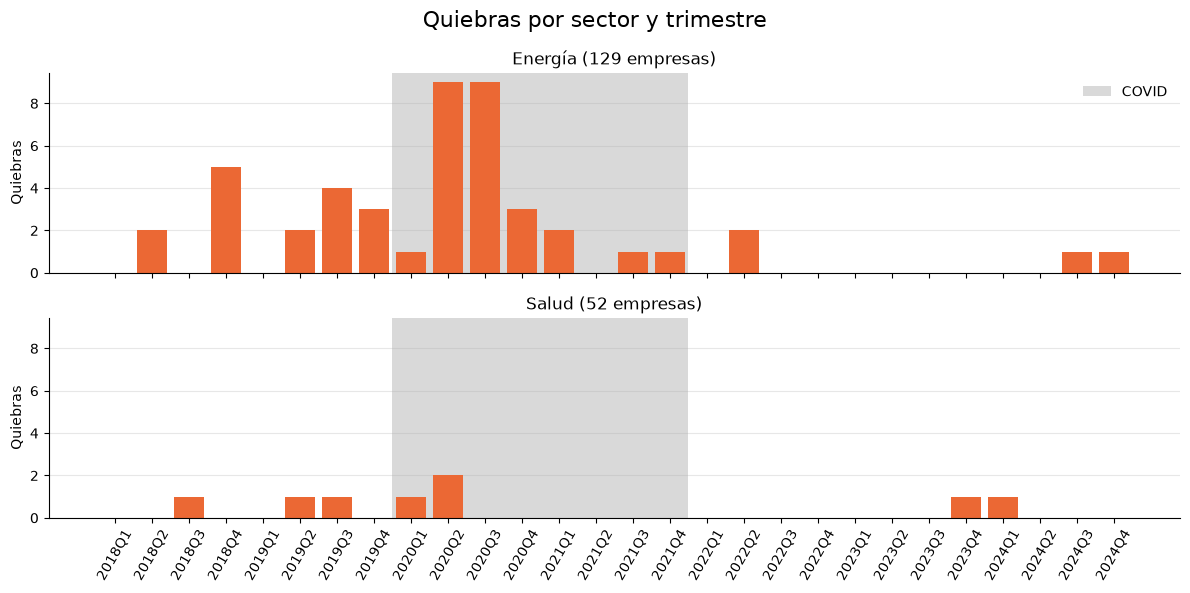

In [42]:
quiebras = pd.crosstab(
    pd.to_datetime(quebradas["fecha_quiebra"]).dt.to_period("Q"),
    quebradas["sector"],
).reindex(TRIMESTRES, fill_value=0)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)

for ax, sector in zip(axes, ["energia", "salud"]):
    ax.spines[["top", "right"]].set_visible(False)
    ax.bar(quiebras.index.astype(str), quiebras[sector], color=COLORES["quiebra"])
    sombrear_covid(ax, quiebras.index)
    ax.set_title(
        f"{NOMBRES[sector]} ({n_empresas[sector]} empresas)",
    )
    ax.set_ylabel("Quiebras")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)


axes[0].legend(frameon=False)
axes[-1].tick_params(axis="x", rotation=60)
fig.suptitle("Quiebras por sector y trimestre", fontsize=16)
fig.tight_layout()

### Trimestres entre la última fila y la quiebra

Para cada empresa de `panel_qc` que quiebra: trimestre de `fecha_quiebra` menos trimestre de su última fila. Desde el trimestre de la quiebra no hay filas (`docs/decisions.md`, sección 13), así que el mínimo es 1: la última fila es el trimestre anterior a la quiebra. Un valor mayor indica que la empresa se quedó sin filas antes de quebrar.

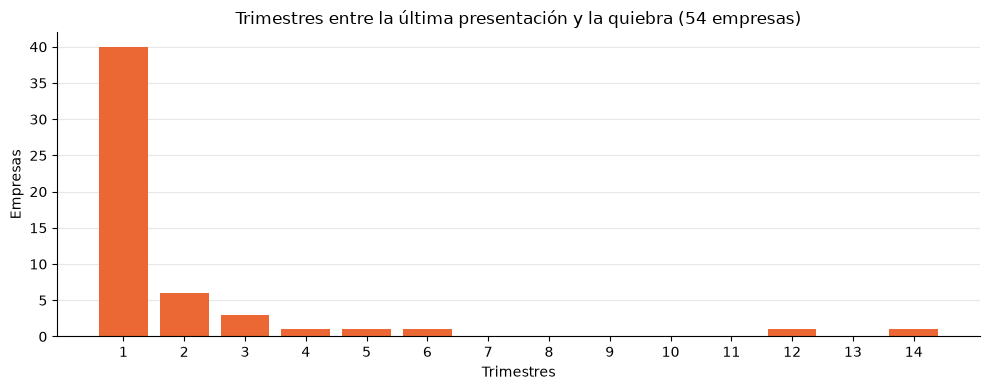

In [43]:
ultimas = (
    panel_qc[panel_qc["fecha_quiebra"].notna()]
    .groupby("cik")
    .agg(ultima_fila=("trimestre", "max"), fecha_quiebra=("fecha_quiebra", "first"))
)
# Period -> int counts quarters since 1970Q1, so the difference is in quarters
hasta_quiebra = pd.to_datetime(ultimas["fecha_quiebra"]).dt.to_period("Q").astype(
    int
) - pd.PeriodIndex(ultimas["ultima_fila"], freq="Q").astype(int)
por_distancia = hasta_quiebra.value_counts().reindex(
    range(1, hasta_quiebra.max() + 1), fill_value=0
)

fig, ax = plt.subplots(figsize=(10, 4))
barras = ax.bar(
    por_distancia.index.astype(str), por_distancia, color=COLORES["quiebra"]
)
ax.set_title(
    f"Trimestres entre la última presentación y la quiebra ({len(ultimas)} empresas)"
)
ax.set_xlabel("Trimestres")
ax.set_ylabel("Empresas")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()

Lo mismo, por sector. Los dos paneles comparten los ejes.

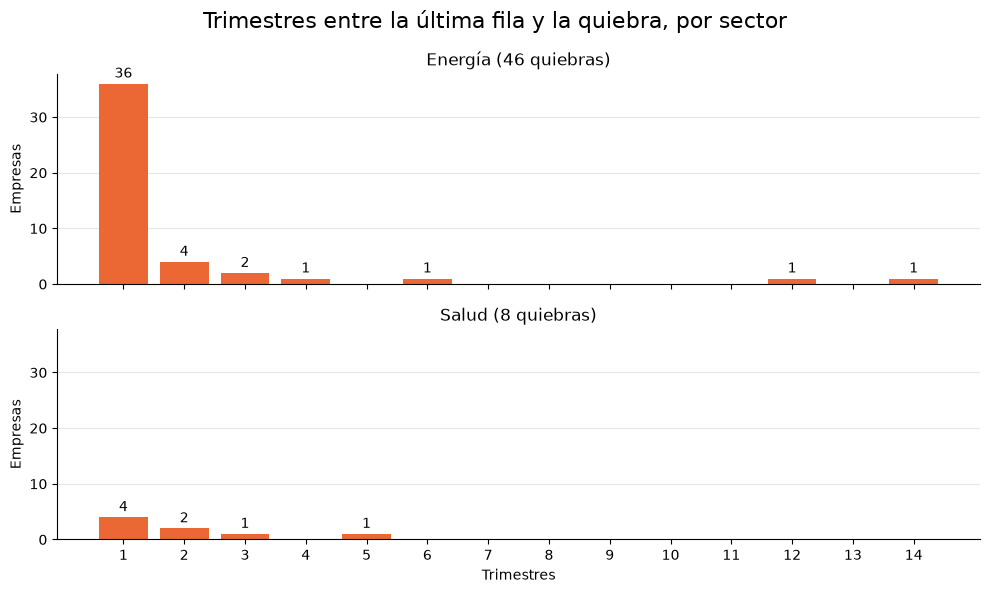

In [44]:
por_sector = pd.crosstab(
    hasta_quiebra, empresas.loc[hasta_quiebra.index, "sector"]
).reindex(range(1, hasta_quiebra.max() + 1), fill_value=0)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, sharey=True)
for ax, sector in zip(axes, ["energia", "salud"]):
    barras = ax.bar(
        por_sector.index.astype(str), por_sector[sector], color=COLORES["quiebra"]
    )
    ax.bar_label(
        barras, labels=[str(n) if n else "" for n in por_sector[sector]], padding=2
    )
    ax.set_title(f"{NOMBRES[sector]} ({por_sector[sector].sum()} quiebras)")
    ax.set_ylabel("Empresas")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

axes[-1].set_xlabel("Trimestres")
fig.suptitle("Trimestres entre la última fila y la quiebra, por sector", fontsize=16)
fig.tight_layout()

## Datos faltantes

El panel tiene cuatro dimensiones: sector × empresa × trimestre × concepto. No se pueden mirar juntas, así que se arma una tabla larga (`largo`) con una fila por empresa, trimestre y concepto, y una columna `falta` (el valor es NaN). Cada vista agrupa por algunas dimensiones y promedia las demás:

| Vista | Se ve | Se promedia |
|---|---|---|
| 1 | concepto × sector | empresas y trimestres |
| 2 | concepto × trimestre | empresas |
| 3 | empresa × concepto | trimestres |

Solo cuentan las filas que existen. Que una empresa no tenga filas desde su quiebra no es un faltante: es la regla del panel (`docs/decisions.md`, sección 13).

Por ahora solo los 11 conceptos. Los ratios heredan los faltantes de sus conceptos y se analizan después.

In [45]:
CONCEPTOS = [
    c for c in CONCEPTS if c != "costo_ventas"
]  # costo_ventas is not in the panel
AZUL = "#2a78d6"
ETIQUETAS = {c: c.replace("_", " ").capitalize() for c in CONCEPTOS}  # for the axes

largo = panel_qc.melt(
    id_vars=["cik", "sector", "trimestre"], value_vars=CONCEPTOS, var_name="concepto"
)
largo["falta"] = largo["value"].isna()

# share of each company's quarters without the concept
por_empresa = largo.groupby(["sector", "cik", "concepto"])["falta"].mean()


### Vista 1: faltantes por concepto y sector

Porcentaje de celdas (empresa × trimestre) sin dato. Ordenado por energía.

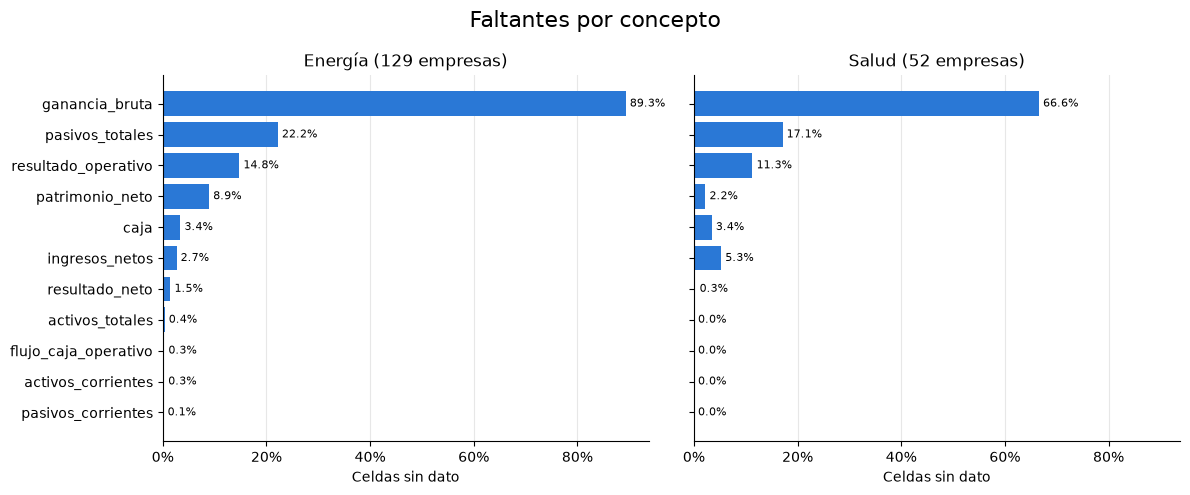

In [46]:
from matplotlib.ticker import PercentFormatter

vista1 = (
    largo.groupby(["concepto", "sector"])["falta"]
    .mean()
    .unstack()
    .sort_values("energia")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, sharex=True)
for ax, sector in zip(axes, ["energia", "salud"]):
    barras = ax.barh(vista1.index, vista1[sector], color=AZUL)
    ax.bar_label(
        barras, labels=[f"{v:.1%}" for v in vista1[sector]], padding=3, fontsize=8
    )
    ax.set_title(f"{NOMBRES[sector]} ({n_empresas[sector]} empresas)")
    ax.set_xlabel("Celdas sin dato")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
fig.suptitle("Faltantes por concepto", fontsize=16)
fig.tight_layout()
# vista1

### Vista 2: faltantes por concepto y trimestre

Un panel por concepto y una línea por sector. Si el faltante de un concepto cambia en el tiempo, suele ser un cambio de tag (por ejemplo, empresas que empiezan a reportar `Liabilities`).

Cada panel tiene su propia escala vertical: con una escala común, la ganancia bruta (cerca del 90%) aplasta a todos los demás conceptos.

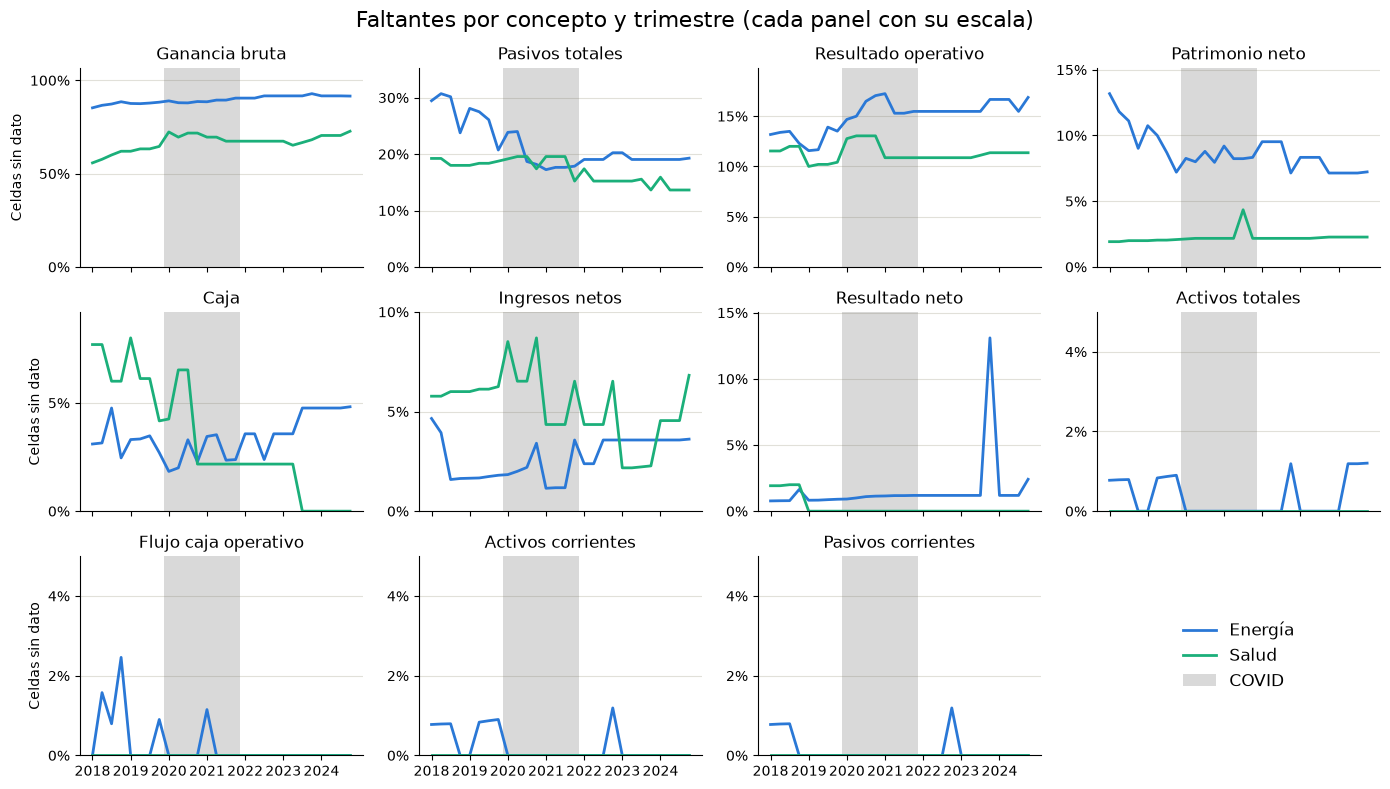

In [47]:
from matplotlib.ticker import MaxNLocator

vista2 = largo.groupby(["sector", "concepto", "trimestre"])["falta"].mean().unstack()
SECTORES = {"energia": AZUL, "salud": "#1baf7a"}
orden = vista1.index[::-1]  # the most missing first, as in vista 1
inicio_fin_covid = [
    list(vista2.columns).index(q) + d for q, d in zip(COVID, (-0.5, 0.5))
]

fig, axes = plt.subplots(3, 4, figsize=(14, 8), sharex=True)
for ax, concepto in zip(axes.flat, orden):
    for sector, color in SECTORES.items():
        ax.plot(
            vista2.columns,
            vista2.loc[(sector, concepto)],
            color=color,
            linewidth=2,
            label=NOMBRES[sector],
        )
    ax.axvspan(
        *inicio_fin_covid, color="#6b6b6b", alpha=0.25, linewidth=0, label="COVID"
    )
    ax.set_title(ETIQUETAS[concepto])
    ax.set_ylim(0, max(0.05, vista2.xs(concepto, level="concepto").max().max() * 1.15))
    ax.yaxis.set_major_locator(MaxNLocator(4, steps=[1, 2, 5, 10]))  # clean ticks
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xticks(range(0, N_TRIMESTRES, 4), [str(t.year) for t in TRIMESTRES[::4]])
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e1e0d9")
    ax.set_axisbelow(True)
for ax in axes[:, 0]:
    ax.set_ylabel("Celdas sin dato")
axes.flat[-1].axis("off")
axes.flat[-1].legend(
    *axes.flat[0].get_legend_handles_labels(), loc="center", frameon=False, fontsize=12
)
fig.suptitle(
    "Faltantes por concepto y trimestre (cada panel con su escala)", fontsize=16
)
fig.tight_layout()

### Vista 3: ¿falta siempre o a veces?

Para cada empresa y concepto, el porcentaje de sus trimestres sin dato:

- `siempre está`: 0%.
- `a veces falta`: entre 0% y 100%. Son trimestres sueltos; es el único caso donde tiene sentido completar con el valor anterior.
- `nunca está`: 100%. La empresa no reporta ese concepto con ningún tag (faltante estructural).

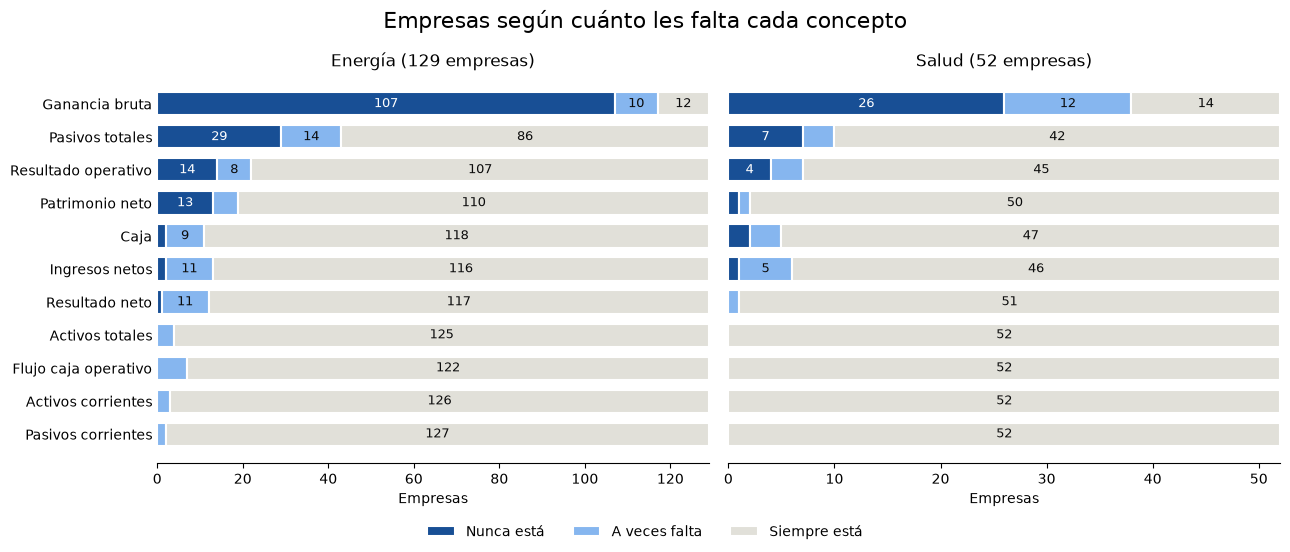

In [48]:
# order: from the problem to the normal case, so the bars start with "nunca está"
ESTADOS = {
    "nunca está": ("#184f95", "white"),
    "a veces falta": ("#86b6ef", "#0b0b0b"),
    "siempre está": ("#e1e0d9", "#0b0b0b"),
}

estado = pd.cut(
    por_empresa,
    [-0.01, 0, 0.999, 1],
    labels=["siempre está", "a veces falta", "nunca está"],
)
vista3 = estado.groupby(["sector", "concepto"], observed=False).value_counts().unstack()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, sector in zip(axes, ["energia", "salud"]):
    datos = vista3.loc[sector].reindex(vista1.index)
    izquierda = 0
    for nombre, (color, tinta) in ESTADOS.items():
        barras = ax.barh(
            [ETIQUETAS[c] for c in datos.index],
            datos[nombre],
            left=izquierda,
            height=0.7,
            color=color,
            label=nombre.capitalize(),
            edgecolor="white",
            linewidth=1.5,
        )
        # the count goes inside the segment only if it fits (>= 6% of the companies)
        ax.bar_label(
            barras,
            labels=[
                str(n) if n >= 0.06 * n_empresas[sector] else "" for n in datos[nombre]
            ],
            label_type="center",
            color=tinta,
            fontsize=9,
        )
        izquierda = izquierda + datos[nombre]
    ax.set_xlim(0, n_empresas[sector])
    ax.set_title(f"{NOMBRES[sector]} ({n_empresas[sector]} empresas)")
    ax.set_xlabel("Empresas")
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
fig.legend(
    *axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False
)
fig.suptitle("Empresas según cuánto les falta cada concepto", fontsize=16)
fig.tight_layout(rect=(0, 0.05, 1, 1))  # leaves room for the legend below
# vista3.unstack(0)